**Practice**

**Tabular data ingestion (Heart Disease)**

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn wfdb pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 5.9 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

**Dataset**

In [3]:
import os
import zipfile

zip_path="/content/heart+disease.zip"
extract_path="/content/heart_disease"
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
  zip_ref.extractall(extract_path)
  print("Dataset extracted successfully!")


Dataset extracted successfully!


**Inspect schema, handle missing values, map target to binary (0 vs 1+).**

In [4]:
columns = [
    "age",
    "gender",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "target"
]

In [5]:
df=pd.read_csv("/content/heart_disease/processed.cleveland.data", names=columns)

In [6]:
df.head()

,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [7]:
df.shape

(303, 14)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   gender    303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    object 
 12  thal      303 non-null    object 
 13  target    303 non-null    int64  
dtypes: float64(11), int64(1), object(2)
memory usage: 33.3+ KB


In [9]:
df.describe()

,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,4.000000


In [10]:
df["ca"].value_counts()

,count
ca,
0.0,176
1.0,65
2.0,38
3.0,20
?,4


**Check missing values**

In [11]:
df.isnull().sum()

,0
age,0
gender,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [12]:
df.replace("?", np.nan, inplace=True)

In [13]:
df.isnull().sum()

,0
age,0
gender,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [14]:
df=df.apply(pd.to_numeric)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   gender    303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [16]:
df[["ca", "thal"]].isnull().sum()

,0
ca,4
thal,2


In [17]:
df.fillna(df.median(), inplace=True)

In [18]:
df.isnull().sum()

,0
age,0
gender,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [19]:
df["target"].value_counts()

,count
target,
0,164
1,55
2,36
3,35
4,13


In [20]:
df["target"]=(df["target"]>0).astype(int)

In [21]:
df["target"].value_counts()

,count
target,
0,164
1,139


In [22]:
df.describe()

,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.663366,4.722772,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.934375,1.938383,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


**EDA**

**Histogram**

<function matplotlib.pyplot.show(close=None, block=None)>

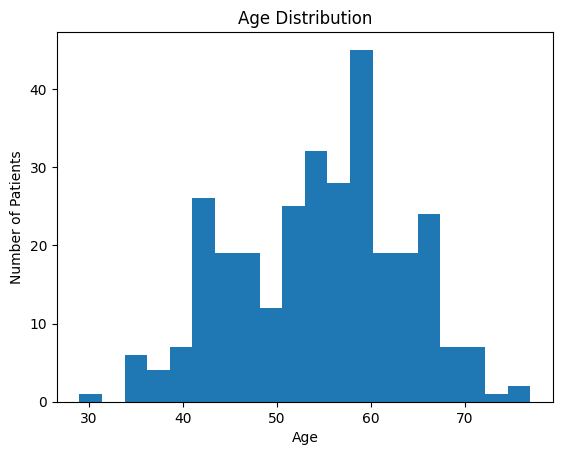

In [23]:
plt.hist(df["age"], bins=20)
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.title("Age Distribution")
plt.show

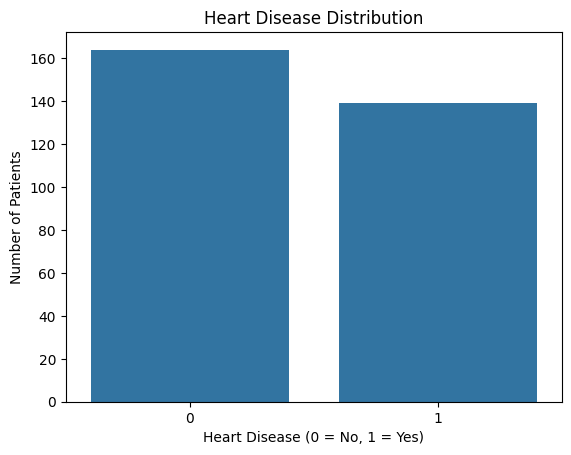

In [24]:
sns.countplot(x="target", data=df)
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.title("Heart Disease Distribution")
plt.show()


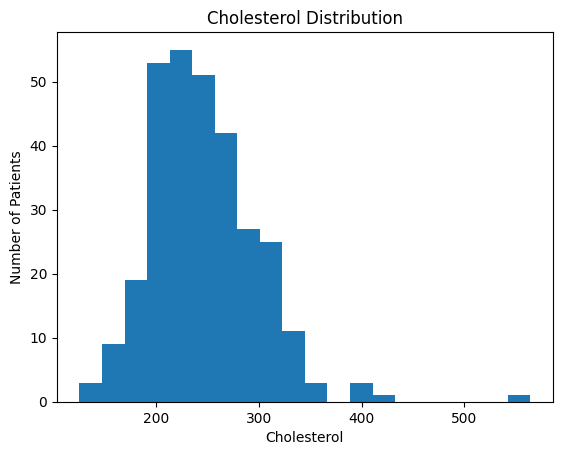

In [25]:
plt.hist(df["chol"], bins=20)
plt.xlabel("Cholesterol")
plt.ylabel("Number of Patients")
plt.title("Cholesterol Distribution")
plt.show()

In [26]:
df.columns

Index(['age', 'gender', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

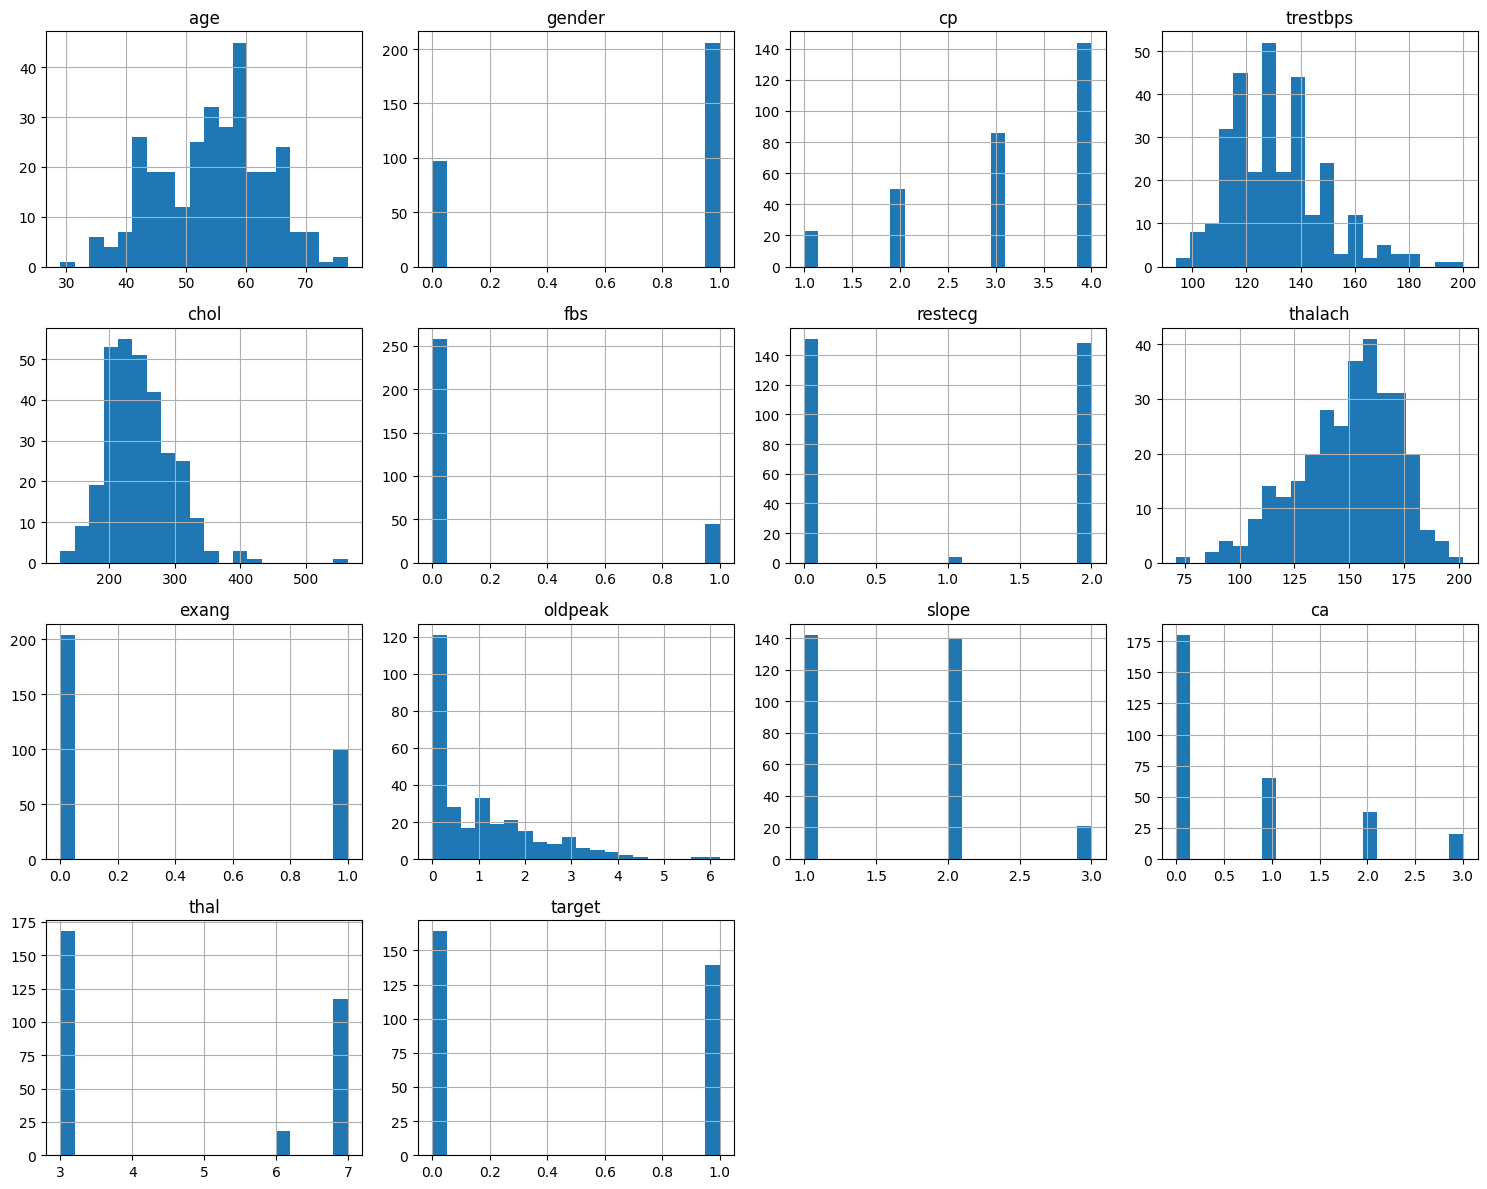

In [27]:
df.hist(figsize=(15, 12), bins=20)
plt.tight_layout()
plt.show()

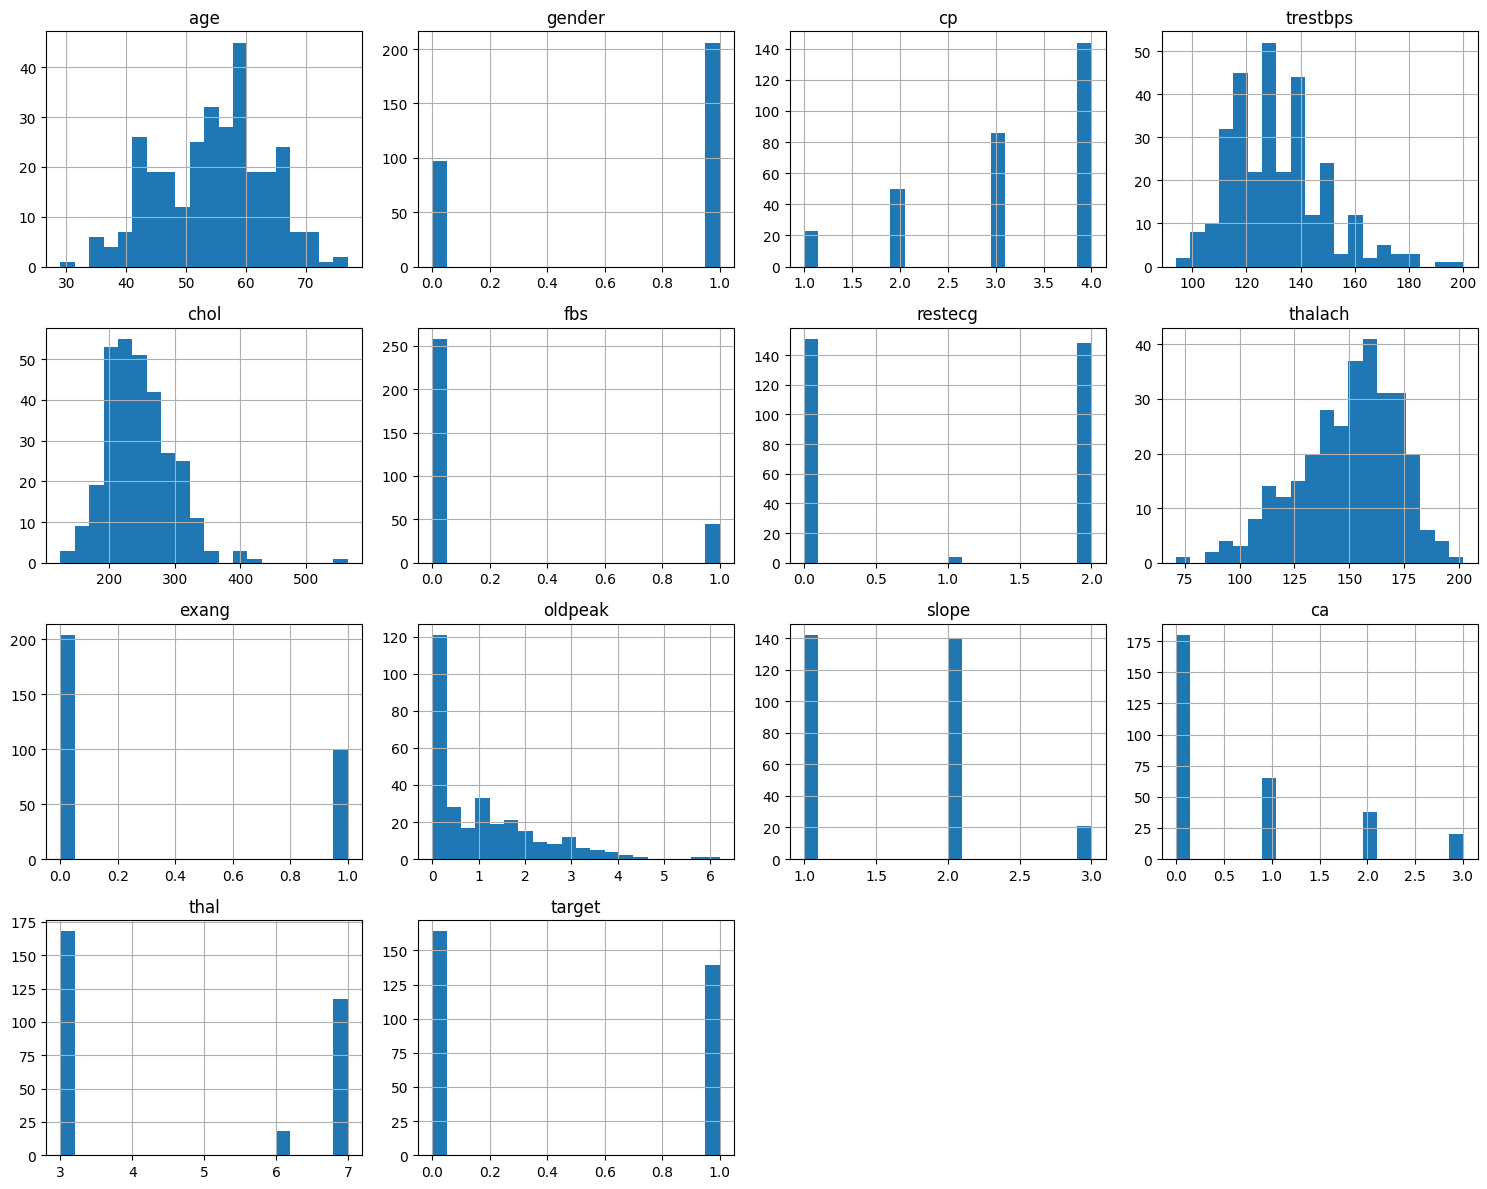

In [28]:
df.hist(figsize=(15, 12), bins=20)
plt.tight_layout()
plt.show()

**Correlation**

In [29]:
correlation = df.corr()
correlation

,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.097542,0.104139,0.284946,0.208950,0.118530,0.148868,-0.393806,0.091661,0.203805,0.161770,0.365323,0.128303,0.223120
gender,-0.097542,1.000000,0.010084,-0.064456,-0.199915,0.047862,0.021647,-0.048663,0.146201,0.102173,0.037533,0.086048,0.380581,0.276816
cp,0.104139,0.010084,1.000000,-0.036077,0.072319,-0.039975,0.067505,-0.334422,0.384060,0.202277,0.152050,0.233117,0.262089,0.414446
trestbps,0.284946,-0.064456,-0.036077,1.000000,0.130120,0.175340,0.146560,-0.045351,0.064762,0.189171,0.117382,0.097528,0.134424,0.150825
chol,0.208950,-0.199915,0.072319,0.130120,1.000000,0.009841,0.171043,-0.003432,0.061310,0.046564,-0.004062,0.123726,0.018351,0.085164
fbs,0.118530,0.047862,-0.039975,0.175340,0.009841,1.000000,0.069564,-0.007854,0.025665,0.005747,0.059894,0.140764,0.064625,0.025264
restecg,0.148868,0.021647,0.067505,0.146560,0.171043,0.069564,1.000000,-0.083389,0.084867,0.114133,0.133946,0.131749,0.024325,0.169202
thalach,-0.393806,-0.048663,-0.334422,-0.045351,-0.003432,-0.007854,-0.083389,1.000000,-0.378103,-0.343085,-0.385601,-0.265699,-0.274142,-0.417167
exang,0.091661,0.146201,0.384060,0.064762,0.061310,0.025665,0.084867,-0.378103,1.000000,0.288223,0.257748,0.145788,0.325240,0.431894
oldpeak,0.203805,0.102173,0.202277,0.189171,0.046564,0.005747,0.114133,-0.343085,0.288223,1.000000,0.577537,0.301067,0.342405,0.424510


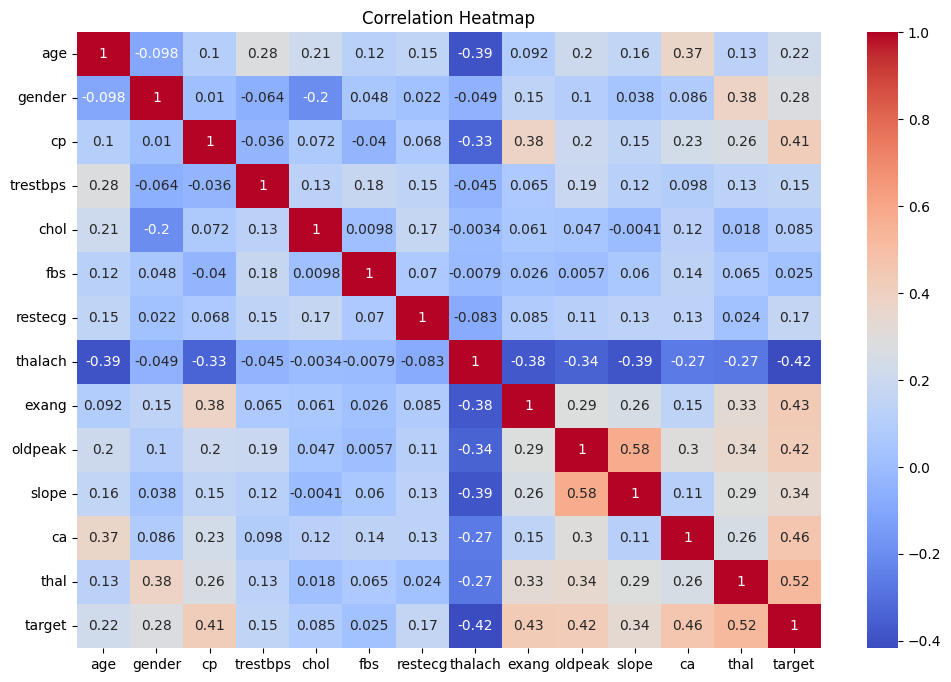

In [30]:
plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

**Train a baseline classifier (e.g., logistic regression) to predict heart disease presence.**

In [31]:
X=df.drop("target", axis=1)

In [32]:
y=df["target"]

In [33]:
y.shape

(303,)

In [34]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [35]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)


LogisticRegression(max_iter=1000)

In [36]:
y_pred=model.predict(X_test)

In [37]:
y_pred

array([0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1])

**Evaluate with accuracy, ROC AUC, confusion matrix.**

In [38]:
from sklearn.metrics import accuracy_score
accuracy=accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.8688524590163934


In [39]:
y_prob=model.predict_proba(X_test)[:, 1]
y_prob

array([0.19679502, 0.72537077, 0.07293413, 0.03845314, 0.56195792,
       0.03793582, 0.1231047 , 0.22428696, 0.80919798, 0.32104784,
       0.87436479, 0.02005986, 0.09104264, 0.98529   , 0.89966123,
       0.9823108 , 0.91621237, 0.30178454, 0.85450096, 0.93968693,
       0.59291982, 0.10967289, 0.79607679, 0.77559673, 0.7403438 ,
       0.07832052, 0.1368857 , 0.9780191 , 0.30046764, 0.89369754,
       0.36904444, 0.96120864, 0.82884301, 0.33900319, 0.1565868 ,
       0.93133582, 0.27269248, 0.30598736, 0.09342699, 0.75071175,
       0.97760134, 0.99693447, 0.97567012, 0.92643043, 0.10135131,
       0.09443823, 0.87756692, 0.045505  , 0.99735963, 0.34878408,
       0.04661181, 0.96659014, 0.66079383, 0.16009289, 0.34645721,
       0.94499969, 0.99501241, 0.54786519, 0.04208032, 0.03089249,
       0.98544109])

In [40]:
from sklearn.metrics import roc_auc_score
roc_auc=roc_auc_score(y_test, y_prob)
print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9523809523809524


In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm=confusion_matrix(y_test, y_pred)
cm


array([[27,  6],
       [ 2, 26]])

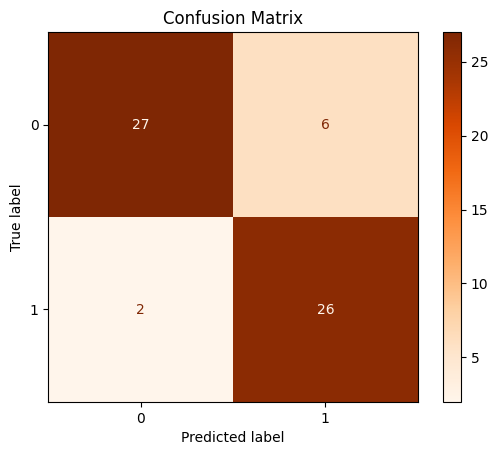

In [42]:
ConfusionMatrixDisplay(cm).plot(cmap="Oranges")
plt.title("Confusion Matrix")
plt.show()

In [43]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.82      0.87        33
           1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



**TEXT SIGNAL**

In [56]:
# Create a sample clinical note
text = """
Patient has chest pain, shortness of breath and fatigue.
"""

# Save it to a text file
with open("patient_note.txt", "w") as f:
    f.write(text)

# Read the text file
with open("patient_note.txt", "r") as f:
    note = f.read()

print("Clinical Note:")
print(note)

# Tokenization
words = note.lower().split()

print("Words:")
print(words)

# Word frequency
from collections import Counter

frequency = Counter(words)

print("\nWord Frequency:")
print(frequency)

Clinical Note:

Patient has chest pain, shortness of breath and fatigue.

Words:
['patient', 'has', 'chest', 'pain,', 'shortness', 'of', 'breath', 'and', 'fatigue.']

Word Frequency:
Counter({'patient': 1, 'has': 1, 'chest': 1, 'pain,': 1, 'shortness': 1, 'of': 1, 'breath': 1, 'and': 1, 'fatigue.': 1})


**IMAGE DATA**

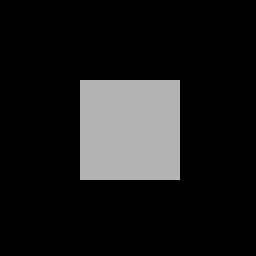

Format: None
Size: (256, 256)
Mode: L
New Size: (128, 128)


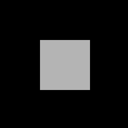

In [57]:
import numpy as np
from PIL import Image

# Create a 256 × 256 black image
image_array = np.zeros((256, 256), dtype=np.uint8)

# Add a gray square
image_array[80:180, 80:180] = 180

# Convert NumPy array into an image
image = Image.fromarray(image_array)

# Save image
image.save("medical_image.png")

# Display image
display(image)

# Image information
print("Format:", image.format)
print("Size:", image.size)
print("Mode:", image.mode)

# Resize image
resized_image = image.resize((128, 128))

print("New Size:", resized_image.size)

display(resized_image)

**ECG Signal**

In [46]:
!pip -q install wfdb

In [45]:
!wget --no-check-certificate https://physionet.org/files/mitdb/1.0.0/100.dat
!wget --no-check-certificate https://physionet.org/files/mitdb/1.0.0/100.hea
!wget --no-check-certificate https://physionet.org/files/mitdb/1.0.0/100.atr

--2026-09-11 02:26:49--  https://physionet.org/files/mitdb/1.0.0/100.dat
Resolving physionet.org (physionet.org)... 18.25.8.254
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1950000 (1.9M) [application/octet-stream]
Saving to: ‘100.dat’

100.dat             100%[===================>]   1.86M   282KB/s    in 6.7s    

2026-09-11 02:26:56 (286 KB/s) - ‘100.dat’ saved [1950000/1950000]

--2026-09-11 02:26:56--  https://physionet.org/files/mitdb/1.0.0/100.hea
Resolving physionet.org (physionet.org)... 18.25.8.254
Connecting to physionet.org (physionet.org)|18.25.8.254|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 143 [text/plain]
Saving to: ‘100.hea’

100.hea             100%[===================>]     143  --.-KB/s    in 0s      

2026-09-11 02:26:56 (53.0 MB/s) - ‘100.hea’ saved [143/143]

--2026-09-11 02:26:56--  https://physionet.org/files/mitdb/1.0.0/100.atr
Resolving physion

In [47]:
import wfdb
record = wfdb.rdrecord("100")

In [48]:
annotation = wfdb.rdann("100", "atr")

In [49]:
print(record)
print("Signal shape:", record.p_signal.shape)
print("Sampling frequency:", record.fs)

Signal shape: (650000, 2)
Sampling frequency: 360


In [63]:
record.fs

360

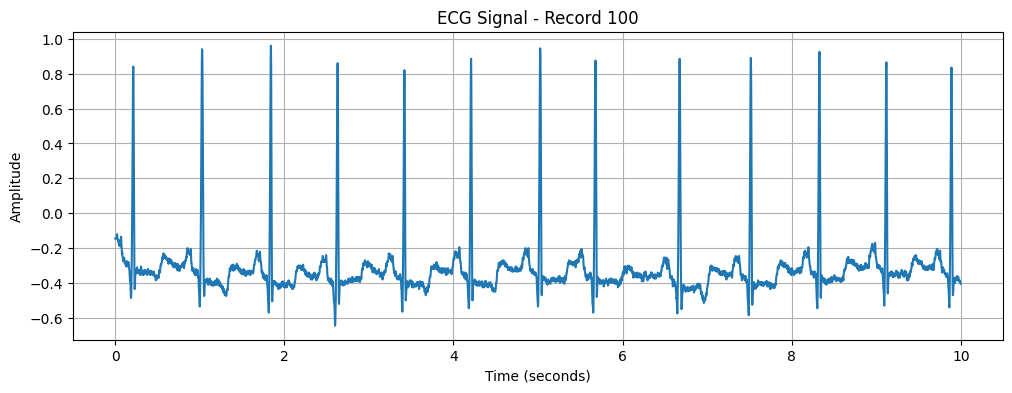

In [60]:
# Plot first 10 seconds
samples = int(10 * record.fs)
#Take the first 3600 samples
signal = record.p_signal[:samples, 0]
time = np.arange(samples) / record.fs

plt.figure(figsize=(12, 4))
plt.plot(time, signal)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("ECG Signal - Record 100")
plt.grid()
plt.show()

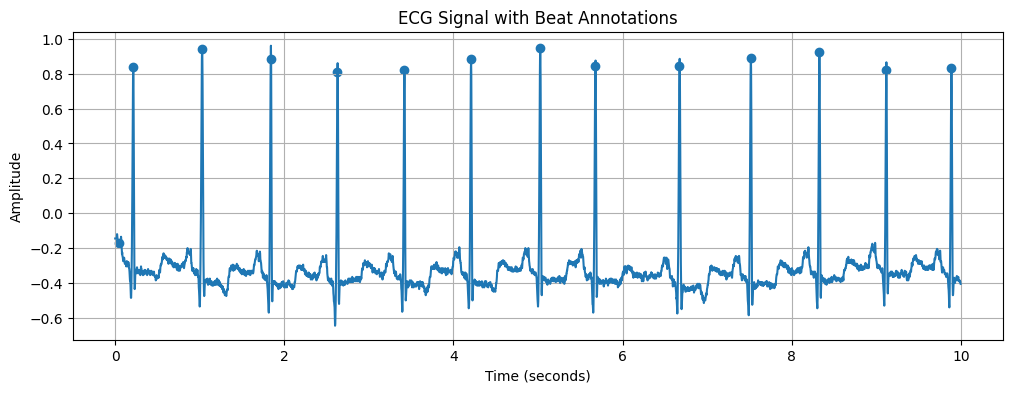

In [59]:
# Get annotation times
ann_time = annotation.sample / record.fs

# Only annotations within first 10 seconds
mask = ann_time < 10
plt.figure(figsize=(12, 4))
plt.plot(time, signal)
plt.scatter(
    ann_time[mask],
    record.p_signal[annotation.sample[mask], 0]
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.title("ECG Signal with Beat Annotations")

plt.grid()

plt.show()

In [61]:
# Calculate time between consecutive annotations
beat_times = annotation.sample / record.fs

rr_intervals = np.diff(beat_times)

# Remove unrealistic intervals because they may caused by incorrect/noisy annotations
rr_intervals = rr_intervals[
    (rr_intervals > 0.25) &
    (rr_intervals < 2)
]

mean_rr = np.mean(rr_intervals)

heart_rate = 60 / mean_rr

print("Mean RR Interval:", round(mean_rr, 3), "seconds")
print("Approximate Heart Rate:", round(heart_rate, 2), "beats/min")

Mean RR Interval: 0.795 seconds
Approximate Heart Rate: 75.51 beats/min
